# Project — River water temperature — *Hub'Eau, température des cours d'eau*
**MSA-DATI07-03 · Advanced EDA & Data Collection** · difficulty ⭐⭐ medium

This is your **project notebook**. It already follows the six-section structure from Session 6 and contains working collection code for this API. Your job: fill every `# TODO` and every *TODO* markdown cell, on **real data you collected yourselves**.

| # | Section | Answers the question… |
|---|---|---|
| 1 | Context & provenance | Where does this data come from, and what question is it for? |
| 2 | Setup & parameters | Can someone else run this and get the same thing? |
| 3 | Collection, ingestion & schema | Did we collect it properly, and is it what we think it is? |
| 4 | Data quality | What is missing, duplicated or weird — and what did we decide? |
| 5 | Exploration | What does the data say? Every figure captioned. |
| 6 | Findings & next steps | What can a modeller trust, and what should they test? |

**Deliverables:** this notebook (Restart & Run All passes, same fingerprint twice) · `requirements.txt` · the 2-page data-quality report (`DATA_QUALITY_REPORT_TEMPLATE.md`) · regular Git commits.

**Possible questions** (pick one or write your own — one per group):
- How does river temperature vary by season and between stations of a département?
- Are summer peaks getting higher across the years you collected?
- How continuous are the sensors: where and when are the gaps?

---
## 1 · Context & provenance

| Field | Your answer |
|---|---|
| **Business question** | How does river water temperature vary by season and between the stations of one département? We describe the seasonal cycle (monthly / seasonal levels and ranges) and compare stations within the same département, to tell a modeller which effects (season, station) any temperature model must account for. |
| **Source** | Hub'Eau (hubeau.eaufrance.fr), French water data API, endpoint `temperature/chronique` (continuous water temperature measured by in-river sensors) |
| **Dataset page / API docs** | https://hubeau.eaufrance.fr/page/api-temperature-continu |
| **Collected by / when** | Group: Abhy, Andrea, Kaled, Sofyan · collection run on *TO CONFIRM (date printed by `collected_at` in Section 3)* |
| **Collection method** | REST API, paginated (`next` link), cached with `requests-cache` (1 week), retry with backoff on 429/5xx, 0.5 s pause between network calls (see Section 3) |
| **Filters applied** | `code_departement = 35` · `date_debut_mesure = 2023-01-01` · `date_fin_mesure = 2023-12-31` · `size = 1000` per page · cap `MAX_ROWS = 20,000` *(TO CONFIRM: copy the final values from the parameters cell)* |
| **Licence / constraints** | Licence Ouverte / Etalab 2.0 (free reuse with attribution: "Source: Hub'Eau") — *TO CONFIRM on the dataset page* |
| **Unit of observation** | One row = one temperature measurement at one station, at one date and time *(TO CONFIRM on the data: check that (station, date, time) is unique)* |
| **Known limitations** | (1) **Paging cap**: Hub'Eau refuses to page deeper than ~20,000 rows, so a large query is silently truncated. (2) **Sensor gaps**: sensors fail or are removed, so some stations have missing days or months. (3) **Spikes**: a sensor out of the water (low flow, maintenance) records air temperature. (4) **Different sampling frequencies** between stations (e.g. hourly vs every few hours), so raw row counts are not comparable without resampling. (5) **Point measurements**: one sensor per station, so it says nothing about the rest of the river (depth, banks). (6) **One département, one year**: results do not generalise to other regions or years. |

---
## 2 · Setup & parameters
On Colab, run the install cell once per session.

In [15]:
# Colab / fresh environment only
import importlib.util
missing = [p for p in ("pandera", "requests_cache") if importlib.util.find_spec(p) is None]
if missing:
    !pip install -q "pandera>=0.24" requests-cache

In [16]:
# --- Parameters: the ONLY cell you should need to edit to rerun on new data ---
SEED = 42
DATA_DIR = "data"
REPORT_DIR = "reports"
CACHE_HOURS = 24 * 7                              # re-use API responses for a week
IQR_K = 1.5
MAX_MISSING_SHARE = 0.30

BASE_URL = "https://hubeau.eaufrance.fr/api/v1/temperature/chronique"
QUERY = {"code_departement": "35",               # change to your département
         "date_debut_mesure": "2023-01-01",
         "date_fin_mesure": "2023-12-31",
         "size": 1000}
MAX_ROWS = 20_000                                 # Hub'Eau refuses to page deeper than about 20,000 rows
PAUSE_S = 0.5

In [17]:
import hashlib, json, random, time
from datetime import datetime, timezone
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import pandera
import pandera.pandas as pa
import requests
import requests_cache
from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry

random.seed(SEED); np.random.seed(SEED)
DATA, REPORTS = Path(DATA_DIR), Path(REPORT_DIR)
for p in (DATA / "raw", DATA / "processed", REPORTS):
    p.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid")

for lib in (pd, np, sns, pandera, requests):
    print(f"{lib.__name__:<10}{lib.__version__}")

pandas    2.2.3
numpy     2.1.3
seaborn   0.13.2
pandera   0.35.0
requests  2.32.3


In [18]:
# Write requirements.txt from the packages this notebook imports
from importlib.metadata import version
pkgs = ["pandas", "numpy", "matplotlib", "seaborn", "pandera", "pyarrow", "requests", "requests-cache"]
Path("requirements.txt").write_text("".join(f"{p}=={version(p)}\n" for p in pkgs))
print(Path("requirements.txt").read_text())

pandas==2.2.3
numpy==2.1.3
matplotlib==3.10.0
seaborn==0.13.2
pandera==0.35.0
pyarrow==21.0.0
requests==2.32.3
requests-cache==1.3.3



---
## 3 · Collection, ingestion & schema

### 3.1 A polite, cached HTTP session
- **Cache**: the same request is never sent twice (fast reruns, kind to the API).
- **Retry with backoff** on 429 / 5xx, respecting `Retry-After`.
- **Throttle**: pause between requests that actually hit the network.

In [43]:
session = requests_cache.CachedSession("cache/api", expire_after=CACHE_HOURS * 3600)
session.mount("https://", HTTPAdapter(max_retries=Retry(
    total=5, backoff_factor=1, status_forcelist=[429, 500, 502, 503, 504],
    respect_retry_after_header=True)))
session.headers["User-Agent"] = "MSA-DATI07-student-project/1.0"

def get(url, params=None):
    r = session.get(url, params=params, timeout=30)
    r.raise_for_status()
    if not getattr(r, "from_cache", False):
        time.sleep(PAUSE_S)
    return r

In [44]:
# Which départements fit under the API's 20,000-row limit for our period?
def count_rows(params):
    page = get(BASE_URL, params={**params, "size": 1}).json()
    return page.get("count", 0)

deps = [f"{i:02d}" for i in range(1, 96) if i != 20] + ["2A", "2B"]
counts = pd.DataFrame([
    dict(code_departement=d,
         n_rows=count_rows({"code_departement": d,
                            "date_debut_mesure": QUERY["date_debut_mesure"],
                            "date_fin_mesure": QUERY["date_fin_mesure"]}))
    for d in deps
]).sort_values("n_rows", ascending=False)

fits = counts[(counts.n_rows > 3000) & (counts.n_rows <= MAX_ROWS)]
print(f"{len(fits)} départements have between 3,000 and {MAX_ROWS:,} rows")
fits

14 départements have between 3,000 and 20,000 rows


,code_departement,n_rows
47,49,17520
71,73,14486
46,48,14435
61,63,11753
26,28,11531
63,65,8760
80,82,8760
81,83,8760
64,66,8760
28,30,8760


### 3.2 Collect

In [45]:
def collect_next_link(url, params, items_key, max_rows=MAX_ROWS, verbose=True):
    """APIs that return the URL of the next page in the response ("next").
    We follow it until it disappears or we have enough rows."""
    rows, first = [], True
    while url and len(rows) < max_rows:
        r = get(url, params=params if first else None)   # the next link already contains the params
        page = r.json()
        if first and verbose:
            total = page.get("total", page.get("count"))
            print(f"API reports {total:,} matching rows" if total is not None else "total unknown")
        rows += page.get(items_key, [])
        url, first = page.get("next"), False
    return rows[:max_rows]

In [46]:
# The API's "count" is unreliable and paging stops at ~20,000 rows per query,
# so we collect one station x one month at a time (each chunk is far below the cap).
STATION_URL = "https://hubeau.eaufrance.fr/api/v1/temperature/station"
collected_at = datetime.now(timezone.utc).isoformat(timespec="seconds")

stations = collect_next_link(STATION_URL,
                             {"code_departement": QUERY["code_departement"], "size": 1000},
                             items_key="data", verbose=False)
station_codes = sorted({s["code_station"] for s in stations})
months = pd.date_range(QUERY["date_debut_mesure"], QUERY["date_fin_mesure"], freq="MS")
print(f"{len(station_codes)} stations listed · {len(months)} months to query")

raw_rows, log_rows = [], []
for code in station_codes:
    for start in months:
        end = start + pd.offsets.MonthEnd(0)
        chunk = collect_next_link(BASE_URL, {**QUERY, "code_station": code,
                                             "date_debut_mesure": start.strftime("%Y-%m-%d"),
                                             "date_fin_mesure": end.strftime("%Y-%m-%d")},
                                  items_key="data", verbose=False)
        if chunk:
            log_rows.append(dict(code_station=code, month=start.strftime("%Y-%m"), n_rows=len(chunk)))
        raw_rows += chunk

collection_log = pd.DataFrame(log_rows)
assert (collection_log.n_rows < MAX_ROWS).all(), "a chunk hit the cap: split it further"
print(f"collected {len(raw_rows):,} rows from {collection_log.code_station.nunique()} stations at {collected_at}")
collection_log.pivot(index="code_station", columns="month", values="n_rows")

10 stations listed · 12 months to query
collected 51,425 rows from 8 stations at 2026-11-04T17:20:04+00:00


month,2023-01,2023-02,2023-03,2023-04,2023-05,2023-06,2023-07,2023-08,2023-09,2023-10,2023-11,2023-12
code_station,,,,,,,,,,,,
04162300,744.0,672.0,744.0,720.0,744.0,720.0,689.0,NaN,NaN,NaN,NaN,NaN
04163050,744.0,672.0,744.0,720.0,744.0,720.0,744.0,744.0,720.0,744.0,720.0,744.0
04199370,744.0,672.0,744.0,720.0,744.0,720.0,744.0,744.0,720.0,744.0,720.0,744.0
04204300,744.0,672.0,744.0,720.0,744.0,720.0,744.0,589.0,NaN,NaN,NaN,NaN
04205605,744.0,672.0,744.0,720.0,744.0,720.0,744.0,588.0,NaN,NaN,NaN,NaN
04207400,744.0,672.0,744.0,720.0,744.0,720.0,706.0,NaN,NaN,NaN,NaN,NaN
04212700,NaN,NaN,NaN,NaN,NaN,NaN,37.0,744.0,720.0,744.0,720.0,744.0
04214295,744.0,672.0,744.0,720.0,744.0,720.0,744.0,744.0,720.0,744.0,720.0,744.0


### 3.3 Flatten, save raw Parquet + README

In [47]:
df_raw = pd.json_normalize(raw_rows, sep='_')

In [48]:
raw_path = DATA / "raw" / "raw.parquet"
df_raw.to_parquet(raw_path, index=False)
(DATA / "raw" / "README.md").write_text(f"""# Raw data
- Source: see Section 1 of the notebook
- Collected at (UTC): {collected_at}
- Rows x columns: {df_raw.shape[0]} x {df_raw.shape[1]}
- Columns: {", ".join(df_raw.columns)}
""")
print(df_raw.shape)
df_raw.head()

(51425, 24)


,code_station,libelle_station,uri_station,localisation,longitude,latitude,code_commune,libelle_commune,code_cours_eau,libelle_cours_eau,...,heure_mesure_temp,resultat,code_unite,symbole_unite,code_qualification,libelle_qualification,geometry_type,geometry_crs_type,geometry_crs_properties_name,geometry_coordinates
0,04162300,COUESNON à ROMAZY,https://id.eaufrance.fr/StationMesureEauxSurfa...,PONT D211 - LE MOULIN DU PONT ...,-1.503,48.369096,35244,Romazy,J0--0150,le Couesnon,...,00:00:00,11.200,27,°C,4,Non qualifié,Point,name,urn:ogc:def:crs:OGC:1.3:CRS84,"[-1.5029997483769666, 48.369096241011555]"
1,04162300,COUESNON à ROMAZY,https://id.eaufrance.fr/StationMesureEauxSurfa...,PONT D211 - LE MOULIN DU PONT ...,-1.503,48.369096,35244,Romazy,J0--0150,le Couesnon,...,01:00:00,11.200,27,°C,4,Non qualifié,Point,name,urn:ogc:def:crs:OGC:1.3:CRS84,"[-1.5029997483769666, 48.369096241011555]"
2,04162300,COUESNON à ROMAZY,https://id.eaufrance.fr/StationMesureEauxSurfa...,PONT D211 - LE MOULIN DU PONT ...,-1.503,48.369096,35244,Romazy,J0--0150,le Couesnon,...,02:00:00,11.224,27,°C,4,Non qualifié,Point,name,urn:ogc:def:crs:OGC:1.3:CRS84,"[-1.5029997483769666, 48.369096241011555]"
3,04162300,COUESNON à ROMAZY,https://id.eaufrance.fr/StationMesureEauxSurfa...,PONT D211 - LE MOULIN DU PONT ...,-1.503,48.369096,35244,Romazy,J0--0150,le Couesnon,...,03:00:00,11.224,27,°C,4,Non qualifié,Point,name,urn:ogc:def:crs:OGC:1.3:CRS84,"[-1.5029997483769666, 48.369096241011555]"
4,04162300,COUESNON à ROMAZY,https://id.eaufrance.fr/StationMesureEauxSurfa...,PONT D211 - LE MOULIN DU PONT ...,-1.503,48.369096,35244,Romazy,J0--0150,le Couesnon,...,04:00:00,11.224,27,°C,4,Non qualifié,Point,name,urn:ogc:def:crs:OGC:1.3:CRS84,"[-1.5029997483769666, 48.369096241011555]"


In [49]:
# Some columns contain lists (json_normalize only flattens dicts) — find them first
list_cols = [c for c in df_raw.columns
             if df_raw[c].map(lambda v: isinstance(v, (list, dict))).any()]
print("columns holding lists/dicts:", list_cols)

# Make those cells hashable (as text) just for counting distinct values
hashable = df_raw.copy()
for c in list_cols:
    hashable[c] = hashable[c].map(lambda v: str(v) if isinstance(v, (list, dict)) else v)

# First look: types, missing share, number of distinct values per column
overview = pd.DataFrame({
    "dtype": df_raw.dtypes.astype(str),
    "share_missing": df_raw.isna().mean().round(3),
    "n_unique": hashable.nunique(dropna=True),
}).sort_values("share_missing", ascending=False)
overview

columns holding lists/dicts: ['geometry_coordinates']


,dtype,share_missing,n_unique
code_station,object,0.0,8
libelle_station,object,0.0,8
geometry_crs_properties_name,object,0.0,1
geometry_crs_type,object,0.0,1
geometry_type,object,0.0,1
libelle_qualification,object,0.0,1
code_qualification,object,0.0,1
symbole_unite,object,0.0,1
code_unite,object,0.0,1
resultat,float64,0.0,886


In [50]:
# Compare: what the API says for our exact QUERY vs what we actually collected
page = get(BASE_URL, params=QUERY).json()
print("API count for QUERY:      ", page.get("count"))
print("count_rows() for dept 35: ", count_rows({"code_departement": "35",
                                                "date_debut_mesure": QUERY["date_debut_mesure"],
                                                "date_fin_mesure": QUERY["date_fin_mesure"]}))
print("rows actually collected:  ", len(df_raw))
print("date range collected:     ", df_raw["date_mesure_temp"].min(), "→", df_raw["date_mesure_temp"].max())
print("stations collected:       ", df_raw["code_station"].nunique())

API count for QUERY:       51425
count_rows() for dept 35:  51425
rows actually collected:   51425
date range collected:      2023-01-01 → 2023-12-31
stations collected:        8


In [51]:
print("exact duplicate rows:", df_raw.astype(str).duplicated().sum())
df_raw.groupby("code_station")["date_mesure_temp"].agg(["count", "nunique", "min", "max"])

exact duplicate rows: 0


,count,nunique,min,max
code_station,,,,
04162300,5033,210,2023-01-01,2023-07-29
04163050,8760,365,2023-01-01,2023-12-31
04199370,8760,365,2023-01-01,2023-12-31
04204300,5677,237,2023-01-01,2023-08-25
04205605,5676,237,2023-01-01,2023-08-25
04207400,5050,211,2023-01-01,2023-07-30
04212700,3709,155,2023-07-30,2023-12-31
04214295,8760,365,2023-01-01,2023-12-31


### 3.4 Schema-as-contract

*TODO (Exercise 3 of Session 6)*: write a `pa.DataFrameSchema` for the columns you keep. Requirements: every kept column with a dtype, `strict=True`, **at least 4 domain checks**, `nullable=True` only where justified in a comment. Validate the raw data with `lazy=True` and keep the failure summary for your report.

Columns to look at first (confirm the exact names in `df_raw.columns`): `code_station`, `libelle_station`, `date_mesure_temp`, `heure_mesure_temp`, `resultat`, `code_unite`, `libelle_cours_eau` (TO CONFIRM).

In [52]:
# --- Column selection ---------------------------------------------------------
# Kept: what identifies the station, when it was measured, the value, its unit and
# quality flag, and coordinates. Dropped: URIs (links), the raw `geometry` list
# (duplicates longitude/latitude), and département/region/parameter columns
# (constant: we queried one département and one parameter).
KEEP = ["code_station", "libelle_station", "libelle_cours_eau",
        "date_mesure_temp", "heure_mesure_temp", "resultat",
        "code_unite", "symbole_unite", "code_qualification", "libelle_qualification",
        "longitude", "latitude"]

missing_cols = [c for c in KEEP if c not in df_raw.columns]
print("not found in df_raw:", missing_cols or "none")
KEEP = [c for c in KEEP if c in df_raw.columns]
df_sel = df_raw[KEEP].copy()

# --- Contract -----------------------------------------------------------------
START, END = QUERY["date_debut_mesure"], QUERY["date_fin_mesure"]

schema = pa.DataFrameSchema(
    {
        # 8-digit Sandre station code, kept as text (leading zero matters)
        "code_station": pa.Column(str, pa.Check.str_matches(r"^\d{8}$")),
        "libelle_station": pa.Column(str),
        # nullable: some stations may not be attached to a named river
        "libelle_cours_eau": pa.Column(str, nullable=True),
        # date inside the collection window, ISO format
        "date_mesure_temp": pa.Column(str, [
            pa.Check.str_matches(r"^\d{4}-\d{2}-\d{2}$"),
            pa.Check(lambda s: s.between(START, END), name="inside_collection_window")]),
        "heure_mesure_temp": pa.Column(str, pa.Check.str_matches(r"^\d{2}:\d{2}:\d{2}$")),
        # liquid river water in France: physically between ~0 and 35 °C
        "resultat": pa.Column(float, pa.Check.in_range(-1, 35)),
        "code_unite": pa.Column(str),
        # every measurement should be in °C: check, don't assume
        "symbole_unite": pa.Column(str, pa.Check.isin(["°C"])),
        # nullable: a quality flag may be missing on non-validated (raw) data
        "code_qualification": pa.Column(str, nullable=True),
        "libelle_qualification": pa.Column(str, nullable=True),
        # stations must lie in/around Ille-et-Vilaine
        "longitude": pa.Column(float, pa.Check.in_range(-2.6, -0.9)),
        "latitude": pa.Column(float, pa.Check.in_range(47.5, 48.8)),
    },
    strict=True,
    # one measurement per station per date per hour
    unique=["code_station", "date_mesure_temp", "heure_mesure_temp"],
)
schema = schema.remove_columns([c for c in schema.columns if c not in KEEP])

# --- Validate -----------------------------------------------------------------
fails = None
try:
    schema.validate(df_sel, lazy=True)
    print("✅ raw data passes the contract")
except pa.errors.SchemaErrors as err:
    fails = err.failure_cases
    print(f"❌ {len(fails)} violations")
    display(fails.groupby(["column", "check"]).size().rename("n").reset_index())

not found in df_raw: none
❌ 42 violations


,column,check,n
0,code_station,multiple_fields_uniqueness,14
1,date_mesure_temp,multiple_fields_uniqueness,14
2,heure_mesure_temp,multiple_fields_uniqueness,14


In [53]:
key = ["code_station", "date_mesure_temp", "heure_mesure_temp"]
dup = df_sel[df_sel.duplicated(key, keep=False)].sort_values(key)
print(len(dup), "rows involved")
dup[key + ["resultat", "code_qualification"]]

14 rows involved


,code_station,date_mesure_temp,heure_mesure_temp,resultat,code_qualification
2018,04162300,2023-03-26,03:00:00,10.785,4
2019,04162300,2023-03-26,03:00:00,10.858,4
7051,04163050,2023-03-26,03:00:00,10.296,4
7052,04163050,2023-03-26,03:00:00,10.467,4
15811,04199370,2023-03-26,03:00:00,9.879,4
15812,04199370,2023-03-26,03:00:00,9.756,4
24571,04204300,2023-03-26,03:00:00,11.053,4
24572,04204300,2023-03-26,03:00:00,11.102,4
30248,04205605,2023-03-26,03:00:00,9.952,4
30249,04205605,2023-03-26,03:00:00,10.149,4


---
## 4 · Data quality — measure → decide → log

Every decision gets one `log(...)` call. The table at the end of this section goes into your report.

**What to look for in this dataset:**
- Gaps in each station's time series: sensor failure (MNAR?) or maintenance? Plot measurements per day per station.
- Spikes: a sensor out of the water reads air temperature. How do you detect it — jump size, comparison with neighbours?
- Different sampling frequencies between stations: resample before comparing.
- Units (`code_unite`): all °C? Check, don't assume.

In [54]:
# --- Section 4 thresholds (copy these into the parameters cell of Section 2) ---
TEMP_MIN_C, TEMP_MAX_C = 0.0, 30.0   # liquid river water in Brittany: below 0 or above 30 °C is not plausible
UNIT_CELSIUS = "27"                  # Hub'Eau / SANDRE code for °C
SPIKE_JUMP_C = 2.0                   # a river does not change by more than ~2 °C in one hour
SPIKE_DEV_C = 5.0                    # nor sit 5 °C away from its own 7-day rolling median
MIN_HOURS_PER_DAY = 18               # a daily mean needs at least 18 of the 24 hourly values
MIN_DAYS_PER_MONTH = 20              # a station-month counts as "covered" with >= 20 valid days

decisions = []
def log(column, issue, n_rows, decision, why):
    decisions.append(dict(column=column, issue=issue, n_rows=int(n_rows), decision=decision, why=why))

REQUIRED = ["code_station", "libelle_station", "date_mesure_temp", "heure_mesure_temp",
            "resultat", "code_unite", "code_qualification"]
missing_cols = [c for c in REQUIRED if c not in df_sel.columns]
assert not missing_cols, f"Section 4 needs these columns in KEEP (Section 3.4): {missing_cols}"

df = df_sel.copy()

In [55]:
# combine the date and time labels; the api provides no timezone offset
df["ts"] = pd.to_datetime(df["date_mesure_temp"] + " " + df["heure_mesure_temp"])
df = df.sort_values(["code_station", "ts"]).reset_index(drop=True)
step_h = df.groupby("code_station")["ts"].diff().dt.total_seconds().div(3600)
print("time between two measurements of the same station (hours):")
print(step_h.value_counts().head(6).to_string())

time between two measurements of the same station (hours):
ts
1.0    51403
2.0        7
0.0        7


### 4.1 Duplicates

In [58]:
n_exact = int(df.astype(str).duplicated().sum())
df = df[~df.astype(str).duplicated()].reset_index(drop=True)
log("all", "exact duplicate rows", n_exact, "dropped",
    "identical on every column: the same measurement returned twice by the API pages")
print("exact duplicates:", n_exact)

# Near-duplicates: same station and same timestamp, but different values
key = ["code_station", "ts"]
same_time = df[df.duplicated(key, keep=False)]
print("rows sharing a station + timestamp:", len(same_time))
same_time[["libelle_station", "date_mesure_temp", "heure_mesure_temp", "resultat"]]

exact duplicates: 0
rows sharing a station + timestamp: 14


,libelle_station,date_mesure_temp,heure_mesure_temp,resultat
2018,COUESNON à ROMAZY,2023-03-26,03:00:00,10.785
2019,COUESNON à ROMAZY,2023-03-26,03:00:00,10.858
7051,RAU DE LA CHENELAIS à PLEINE-FOUGERES,2023-03-26,03:00:00,10.296
7052,RAU DE LA CHENELAIS à PLEINE-FOUGERES,2023-03-26,03:00:00,10.467
15811,AFF à PAIMPONT,2023-03-26,03:00:00,9.879
15812,AFF à PAIMPONT,2023-03-26,03:00:00,9.756
24571,VILAINE à CESSON-SEVIGNE,2023-03-26,03:00:00,11.053
24572,VILAINE à CESSON-SEVIGNE,2023-03-26,03:00:00,11.102
30248,ILLET à ERCE-PRES-LIFFRE,2023-03-26,03:00:00,9.952
30249,ILLET à ERCE-PRES-LIFFRE,2023-03-26,03:00:00,10.149


In [59]:
# flag repeated timestamp labels and keep every source reading
n_before = len(df)
df["timestamp_collision"] = df.duplicated(key, keep=False)
n_flagged = int(df["timestamp_collision"].sum())
assert len(df) == n_before
assert n_flagged == len(same_time)
log("ts", "same station + timestamp more than once", n_flagged,
    "flagged; source readings kept",
    "api timestamps have no timezone offset; the daylight-saving cause is unverified, so readings are not averaged")

### 4.2 Impossible values

In [60]:
print("units:", df["code_unite"].value_counts(dropna=False).to_dict())
print("qualification:", df["code_qualification"].value_counts(dropna=False).to_dict())

wrong_unit = df["code_unite"] != UNIT_CELSIUS
impossible = ~df["resultat"].between(TEMP_MIN_C, TEMP_MAX_C)
print(f"not in °C: {int(wrong_unit.sum())} · outside [{TEMP_MIN_C}, {TEMP_MAX_C}] °C: {int(impossible.sum())}")
df[["resultat"]].describe().T

units: {'27': 51425}
qualification: {'4': 51425}
not in °C: 0 · outside [0.0, 30.0] °C: 0


,count,mean,std,min,25%,50%,75%,max
resultat,51425.0,12.961852,4.584606,2.236,9.632,12.582,16.677,24.702


In [61]:
df = df[~wrong_unit].copy()
log("code_unite", "unit other than °C", wrong_unit.sum(), "dropped (none found)",
    "checked, not assumed: mixing units would corrupt every average")
df.loc[impossible[~wrong_unit], "resultat"] = np.nan
log("resultat", f"temperature outside [{TEMP_MIN_C}, {TEMP_MAX_C}] °C", impossible.sum(), "set to NaN (none found)",
    "below 0 °C river water would be ice; above 30 °C is not plausible for Breton rivers")
n_unq = int((df["code_qualification"] == "4").sum())   # 4 = "Non qualifié" (see libelle_qualification)
log("code_qualification", "measurements not validated by the producer ('Non qualifié')", n_unq,
    "kept, flagged as a limitation in the report",
    "every row is unvalidated raw sensor data: no producer has checked them, so our own spike checks matter")

### 4.3 Missingness — mechanism before method

In [62]:
# count unique timestamp labels separately from source rows
per_station = df.groupby(["code_station", "libelle_station"]).agg(
    first=("ts", "min"), last=("ts", "max"), n_rows=("ts", "size"),
    n_timestamps=("ts", "nunique"),
    n_collision_rows=("timestamp_collision", "sum")).reset_index()
start, end = pd.Timestamp(QUERY["date_debut_mesure"]), pd.Timestamp(QUERY["date_fin_mesure"]) + pd.Timedelta(hours=23)
per_station["expected_hours"] = int((end - start) / pd.Timedelta(hours=1)) + 1
per_station["share_missing"] = (1 - per_station["n_timestamps"] / per_station["expected_hours"]).round(3)
per_station["ends_early"] = per_station["last"] < end - pd.Timedelta(days=1)
per_station

,code_station,libelle_station,first,last,n_rows,n_timestamps,n_collision_rows,expected_hours,share_missing,ends_early
0,04162300,COUESNON à ROMAZY,2023-01-01 00:00:00,2023-07-29 16:00:00,5033,5032,2,8760,0.426,True
1,04163050,RAU DE LA CHENELAIS à PLEINE-FOUGERES,2023-01-01 00:00:00,2023-12-31 23:00:00,8760,8759,2,8760,0.000,False
2,04199370,AFF à PAIMPONT,2023-01-01 00:00:00,2023-12-31 23:00:00,8760,8759,2,8760,0.000,False
3,04204300,VILAINE à CESSON-SEVIGNE,2023-01-01 00:00:00,2023-08-25 12:00:00,5677,5676,2,8760,0.352,True
4,04205605,ILLET à ERCE-PRES-LIFFRE,2023-01-01 00:00:00,2023-08-25 11:00:00,5676,5675,2,8760,0.352,True
5,04207400,FLUME à PACE,2023-01-01 00:00:00,2023-07-30 09:00:00,5050,5049,2,8760,0.424,True
6,04212700,SEMNON à PLECHATEL,2023-07-30 11:00:00,2023-12-31 23:00:00,3709,3709,0,8760,0.577,False
7,04214295,ARON à GRAND-FOUGERAY,2023-01-01 00:00:00,2023-12-31 23:00:00,8760,8759,2,8760,0.000,False


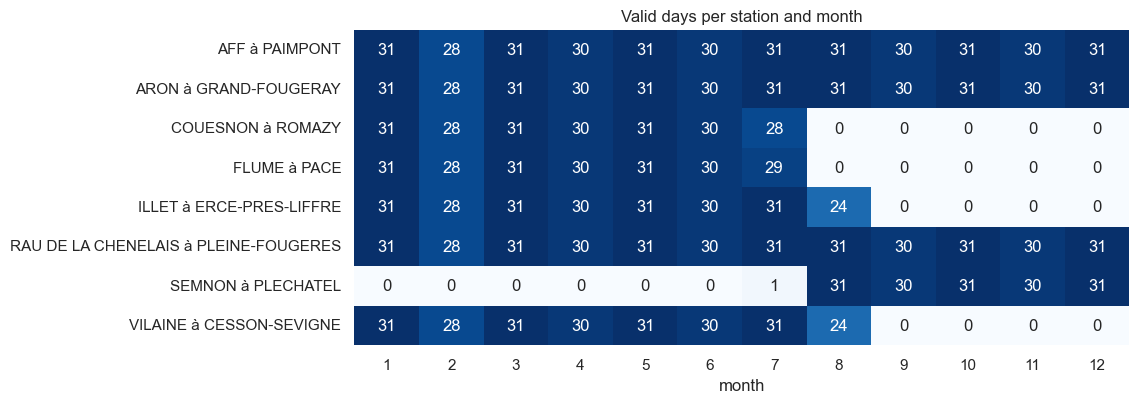

In [42]:
# count unique timestamp labels per day for coverage
daily_valid = df.dropna(subset=["resultat"]).assign(
    day=lambda data: data["ts"].dt.date
)
hours_per_day = (daily_valid.groupby(["libelle_station", "day"])["ts"]
                 .nunique().rename("n_hours"))
valid_days = hours_per_day[hours_per_day >= MIN_HOURS_PER_DAY].reset_index()
valid_days["month"] = pd.to_datetime(valid_days["day"]).dt.month
coverage = valid_days.pivot_table(index="libelle_station", columns="month", values="day",
                                  aggfunc="size", fill_value=0)
fig, ax = plt.subplots(figsize=(10, 0.5 + 0.45 * len(coverage)))
sns.heatmap(coverage, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax)
ax.set(xlabel="month", ylabel="", title="Valid days per station and month")
plt.show()

In [63]:
# Test: does missingness depend on the season (MAR) or is it spread evenly (MCAR)?
season = {12: "winter", 1: "winter", 2: "winter", 3: "spring", 4: "spring", 5: "spring",
          6: "summer", 7: "summer", 8: "summer", 9: "autumn", 10: "autumn", 11: "autumn"}
days_in_month = pd.Series(pd.date_range(start, end.normalize(), freq="D")).dt.month.value_counts().sort_index()
missing_by_season = ((1 - coverage / days_in_month).T
                     .assign(season=lambda t: t.index.map(season))
                     .groupby("season").mean().T.round(2))
missing_by_season[["winter", "spring", "summer", "autumn"]]

season,winter,spring,summer,autumn
libelle_station,,,,
AFF à PAIMPONT,0.00,0.0,0.00,0.0
ARON à GRAND-FOUGERAY,0.00,0.0,0.00,0.0
COUESNON à ROMAZY,0.33,0.0,0.37,1.0
FLUME à PACE,0.33,0.0,0.35,1.0
ILLET à ERCE-PRES-LIFFRE,0.33,0.0,0.08,1.0
RAU DE LA CHENELAIS à PLEINE-FOUGERES,0.00,0.0,0.00,0.0
SEMNON à PLECHATEL,0.67,1.0,0.66,0.0
VILAINE à CESSON-SEVIGNE,0.33,0.0,0.08,1.0


In [64]:
n_missing_labels = int((per_station["expected_hours"] - per_station["n_timestamps"]).sum())
log("ts", "timestamp labels absent vs 24-per-day baseline", n_missing_labels,
    "not imputed; daily summaries require enough unique labels; covered months checked per station",
    "counts unique naive labels; the api timezone is unspecified, so the spring clock change may explain a gap")

### 4.4 Outliers — triage, don't delete

In [65]:
# compare jumps only across one-hour steps
# use a calendar-based seven-day median per station
spike_source = df[["code_station", "ts", "resultat", "timestamp_collision"]].copy()
spike_source["spike_value"] = spike_source["resultat"].where(~spike_source["timestamp_collision"])
by_timestamp = (spike_source.groupby(["code_station", "ts"], as_index=False)
                .agg(resultat=("spike_value", "first"),
                     timestamp_collision=("timestamp_collision", "any")))
spike_parts = []
for _, station in by_timestamp.groupby("code_station", sort=False):
    station = station.sort_values("ts").set_index("ts")
    elapsed_hours = station.index.to_series().diff().dt.total_seconds().div(3600)
    previous_collision = station["timestamp_collision"].shift(fill_value=False)
    station["jump_1h"] = station["resultat"].diff().abs().where(
        elapsed_hours.eq(1) & ~station["timestamp_collision"] & ~previous_collision)
    median_7d = station["resultat"].rolling("7D", center=True, min_periods=24).median()
    station["dev_7d"] = (station["resultat"] - median_7d).abs()
    station["spike_testable"] = station["jump_1h"].notna() | station["dev_7d"].notna()
    station["spike"] = ((station["jump_1h"] > SPIKE_JUMP_C) |
                         (station["dev_7d"] > SPIKE_DEV_C))
    station["ts"] = station.index
    spike_parts.append(station.reset_index(drop=True)[
        ["code_station", "ts", "jump_1h", "dev_7d", "spike_testable", "spike"]])
spike_by_timestamp = pd.concat(spike_parts, ignore_index=True)
df["_row_order"] = np.arange(len(df))
df = df.merge(spike_by_timestamp, on=["code_station", "ts"], how="left",
              validate="many_to_one", sort=False)
df = df.sort_values("_row_order").drop(columns="_row_order").reset_index(drop=True)
assert len(df) == len(spike_source)
print(f"largest eligible 1-hour change: {df['jump_1h'].max():.2f} °C · largest 7-day deviation: {df['dev_7d'].max():.2f} °C")
print(f"flagged as spikes: {int(df['spike'].sum())} · not tested at collisions/gaps: {int((~df['spike_testable']).sum())}")
df.nlargest(8, "dev_7d")[["libelle_station", "ts", "resultat", "jump_1h", "dev_7d", "spike_testable", "spike"]]

largest eligible 1-hour change: 1.16 °C · largest 7-day deviation: 3.96 °C
flagged as spikes: 0 · not tested at collisions/gaps: 14


,libelle_station,ts,resultat,jump_1h,dev_7d,spike_testable,spike
32448,ILLET à ERCE-PRES-LIFFRE,2023-06-25 18:00:00,22.729000,0.167999,3.958000,True,False
32425,ILLET à ERCE-PRES-LIFFRE,2023-06-24 19:00:00,22.775999,0.022999,3.886999,True,False
33553,ILLET à ERCE-PRES-LIFFRE,2023-08-10 19:00:00,22.393000,0.024000,3.883999,True,False
11979,RAU DE LA CHENELAIS à PLEINE-FOUGERES,2023-10-17 10:00:00,9.977000,0.024000,3.881000,True,False
32424,ILLET à ERCE-PRES-LIFFRE,2023-06-24 18:00:00,22.753000,0.503000,3.864000,True,False
33552,ILLET à ERCE-PRES-LIFFRE,2023-08-10 18:00:00,22.368999,0.334999,3.859999,True,False
11978,RAU DE LA CHENELAIS à PLEINE-FOUGERES,2023-10-17 09:00:00,10.001000,0.025000,3.857000,True,False
11977,RAU DE LA CHENELAIS à PLEINE-FOUGERES,2023-10-17 08:00:00,10.026000,0.049000,3.832000,True,False


In [66]:
n_spike = int(df["spike"].sum())
df.loc[df["spike"], "resultat"] = np.nan
log("resultat", f"spikes: > {SPIKE_JUMP_C} °C over an eligible 1-hour step or > {SPIKE_DEV_C} °C from the 7-day median", n_spike,
    "set to NaN (kept in raw data)", "physically too fast for a river: typical of a sensor out of the water reading air")
log("ts", "spike tests skipped at colliding timestamps", int(df["timestamp_collision"].sum()),
    "not evaluated; readings kept", "a collision has no unique timestamp value; source readings remain available")
log("resultat", "largest real deviations below the spike thresholds", int((df["dev_7d"] > 3).sum()),
    "kept", "gradual changes over hours: real weather events, exactly what the seasonal analysis must see")

In [67]:
# average collided readings only within derived timestamp summaries
timestamp_summary = (df.dropna(subset=["resultat"])
                     .groupby(["code_station", "libelle_station", "ts"], as_index=False)
                     .agg(temp_by_timestamp=("resultat", "mean"),
                          temp_min=("resultat", "min"),
                          temp_max=("resultat", "max"),
                          n_source_readings=("resultat", "size"),
                          timestamp_collision=("timestamp_collision", "any")))
daily = (timestamp_summary
         .groupby(["code_station", "libelle_station",
                   timestamp_summary["ts"].dt.normalize().rename("date")])
         .agg(temp_mean=("temp_by_timestamp", "mean"),
              temp_min=("temp_min", "min"), temp_max=("temp_max", "max"),
              n_hours=("ts", "nunique"),
              n_source_readings=("n_source_readings", "sum"),
              n_collision_slots=("timestamp_collision", "sum"))
         .reset_index())
n_short_days = int((daily["n_hours"] < MIN_HOURS_PER_DAY).sum())
daily = daily[daily["n_hours"] >= MIN_HOURS_PER_DAY].reset_index(drop=True)
daily["month"] = daily["date"].dt.month
daily["season"] = daily["month"].map(season)
n_collision_slots = int(timestamp_summary["timestamp_collision"].sum())
log("ts", "repeated timestamp slots in daily summaries", n_collision_slots,
    "combined within derived summaries; source rows kept",
    "each timestamp label gets equal weight; the timezone cause is still unverified")
log("ts", "different sampling frequencies / incomplete days", n_short_days,
    f"resampled to one daily summary per station; days with < {MIN_HOURS_PER_DAY} unique labels dropped",
    "daily coverage counts unique timestamp labels, not source rows")
print(daily.shape)
daily.head()

(2140, 11)


,code_station,libelle_station,date,temp_mean,temp_min,temp_max,n_hours,n_source_readings,n_collision_slots,month,season
0,04162300,COUESNON à ROMAZY,2023-01-01,11.164250,11.053,11.248,24,24,0,1,winter
1,04162300,COUESNON à ROMAZY,2023-01-02,10.730042,10.394,11.029,24,24,0,1,winter
2,04162300,COUESNON à ROMAZY,2023-01-03,9.896708,9.706,10.320,24,24,0,1,winter
3,04162300,COUESNON à ROMAZY,2023-01-04,10.188375,9.854,10.590,24,24,0,1,winter
4,04162300,COUESNON à ROMAZY,2023-01-05,10.884708,10.638,11.078,24,24,0,1,winter


In [68]:
decision_table = pd.DataFrame(decisions, columns=["column", "issue", "n_rows", "decision", "why"])
decision_table.to_csv(REPORTS / "decision_table.csv", index=False)
decision_table

,column,issue,n_rows,decision,why
0,all,exact duplicate rows,0,dropped,identical on every column: the same measuremen...
1,all,exact duplicate rows,0,dropped,identical on every column: the same measuremen...
2,ts,same station + timestamp more than once,14,flagged; source readings kept,api timestamps have no timezone offset; the da...
3,code_unite,unit other than °C,0,dropped (none found),"checked, not assumed: mixing units would corru..."
4,resultat,"temperature outside [0.0, 30.0] °C",0,set to NaN (none found),below 0 °C river water would be ice; above 30 ...
5,code_qualification,measurements not validated by the producer ('N...,51425,"kept, flagged as a limitation in the report",every row is unvalidated raw sensor data: no p...
6,ts,timestamp labels absent vs 24-per-day baseline,18662,not imputed; daily summaries require enough un...,counts unique naive labels; the api timezone i...
7,resultat,spikes: > 2.0 °C over an eligible 1-hour step ...,0,set to NaN (kept in raw data),physically too fast for a river: typical of a ...
8,ts,spike tests skipped at colliding timestamps,14,not evaluated; readings kept,a collision has no unique timestamp value; sou...
9,resultat,largest real deviations below the spike thresh...,115,kept,gradual changes over hours: real weather event...


---
## 5 · Exploration — every figure gets a caption and a *so what*

In [69]:
def show(fig, title, caption, so_what, name):
    fig.suptitle(title, x=0.01, ha="left", fontsize=12, fontweight="bold")
    fig.tight_layout(rect=(0, 0, 1, 0.94))
    fig.text(0.01, -0.04, f"{caption}\n→ {so_what}", ha="left", va="top", fontsize=9, wrap=True)
    fig.savefig(REPORTS / f"{name}.png", bbox_inches="tight", dpi=120)
    plt.show()

clean = df.copy()      # TODO: this should be your cleaned data after Section 4

### 5.1 Univariate

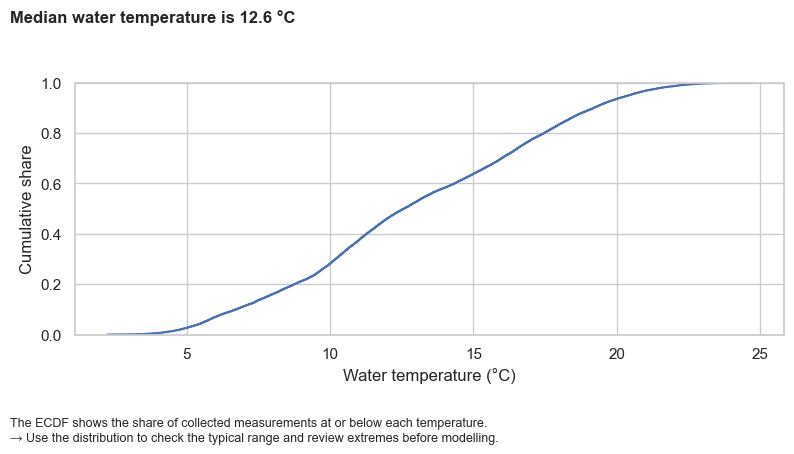

count    51425.000000
mean        12.961852
std          4.584606
min          2.236000
25%          9.632000
50%         12.582000
75%         16.677000
max         24.702000
Name: resultat, dtype: float64

In [70]:
# DONE: one figure showing the distribution of your key variable (ECDF before `.describe()`)
# fig, ax = plt.subplots(figsize=(8, 4))
# ...
# show(fig, "<title that states the finding>", "<what the figure shows>", "<what a modeller should do>", "5_1")
temperature = pd.to_numeric(clean["resultat"], errors="coerce").dropna()
temperature_sorted = np.sort(temperature.to_numpy())
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(temperature_sorted, np.arange(1, len(temperature_sorted) + 1) / len(temperature_sorted))
ax.set_xlabel("Water temperature (°C)")
ax.set_ylabel("Cumulative share")
ax.set_ylim(0, 1)
show(fig, f"Median water temperature is {temperature.median():.1f} °C",
     "The ECDF shows the share of collected measurements at or below each temperature.",
     "Use the distribution to check the typical range and review extremes before modelling.",
     "5_1")
temperature.describe()

### 5.2 Bivariate

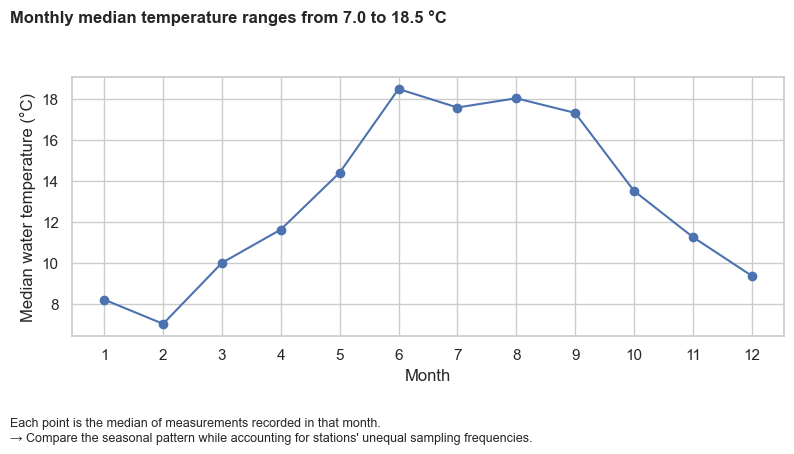

In [71]:
# DONE: one figure showing your key variable against 1–2 explanatory variables
# fig, ax = plt.subplots(figsize=(8, 4))
# ...
# show(fig, "<title that states the finding>", "<what the figure shows>", "<what a modeller should do>", "5_2")
monthly_data = clean[["date_mesure_temp", "resultat"]].copy()
monthly_data["month"] = pd.to_datetime(monthly_data["date_mesure_temp"], errors="coerce").dt.month
monthly_data["temperature"] = pd.to_numeric(monthly_data["resultat"], errors="coerce")
monthly = monthly_data.dropna(subset=["month", "temperature"]).groupby("month")["temperature"].median()
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(monthly.index, monthly.values, marker="o")
ax.set_xticks(range(1, 13))
ax.set_xlabel("Month")
ax.set_ylabel("Median water temperature (°C)")
show(fig, f"Monthly median temperature ranges from {monthly.min():.1f} to {monthly.max():.1f} °C",
     "Each point is the median of measurements recorded in that month.",
     "Compare the seasonal pattern while accounting for stations' unequal sampling frequencies.",
     "5_2")

### 5.3 Multivariate

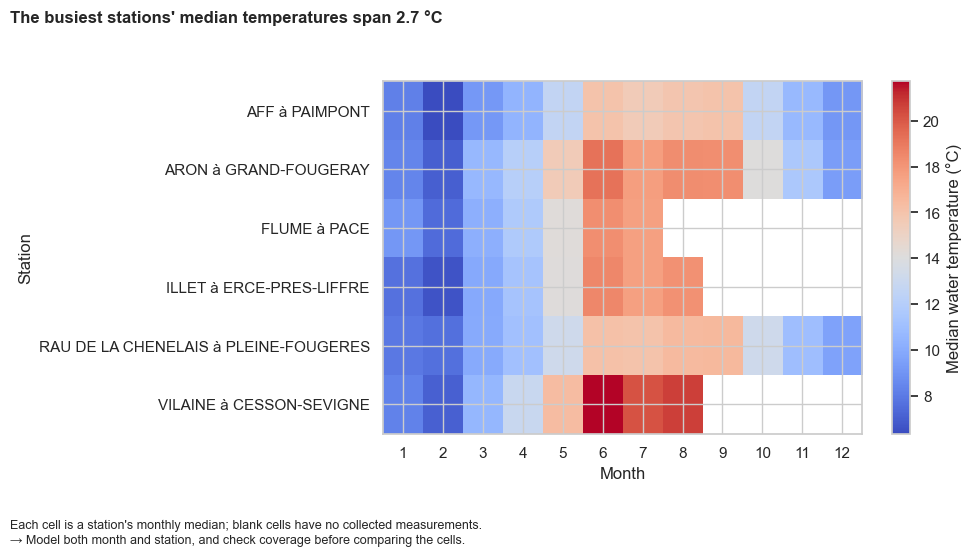

In [72]:
# DONE: one figure showing the correlation structure, or a breakdown by two categories
# fig, ax = plt.subplots(figsize=(8, 4))
# ...
# show(fig, "<title that states the finding>", "<what the figure shows>", "<what a modeller should do>", "5_3")
station_data = clean[["libelle_station", "date_mesure_temp", "resultat"]].copy()
station_data["month"] = pd.to_datetime(station_data["date_mesure_temp"], errors="coerce").dt.month
station_data["temperature"] = pd.to_numeric(station_data["resultat"], errors="coerce")
station_data = station_data.dropna(subset=["libelle_station", "month", "temperature"])
top_stations = station_data["libelle_station"].value_counts().head(6).index
busy = station_data.loc[station_data["libelle_station"].isin(top_stations)]
station_month = busy.pivot_table(index="libelle_station", columns="month", values="temperature", aggfunc="median").reindex(columns=range(1, 13))
station_medians = busy.groupby("libelle_station")["temperature"].median()
station_spread = station_medians.max() - station_medians.min()
fig, ax = plt.subplots(figsize=(10, 5))
image = ax.imshow(station_month.values, aspect="auto", cmap="coolwarm")
ax.set_xticks(range(12))
ax.set_xticklabels(range(1, 13))
ax.set_yticks(range(len(station_month.index)))
ax.set_yticklabels(station_month.index)
ax.set_xlabel("Month")
ax.set_ylabel("Station")
fig.colorbar(image, ax=ax, label="Median water temperature (°C)")
show(fig, f"The busiest stations' median temperatures span {station_spread:.1f} °C",
     "Each cell is a station's monthly median; blank cells have no collected measurements.",
     "Model both month and station, and check coverage before comparing the cells.",
     "5_3")

---
## 6 · Findings, what cannot be trusted, next steps

*TODO*

**Three findings** — each with the figure it comes from and what it means for modelling.
1.
2.
3.

**What cannot be trusted** — column, subset, and why.
-
-

**Five testable hypotheses** — variable, direction, population, test.
- H1:
- H2:
- H3:
- H4:
- H5:

### Final contract & fingerprint
*TODO*: write `clean_schema` for the data a modeller receives (it may differ from the raw schema). Then **Restart & Run All twice**: the fingerprint must be identical.

In [ ]:
clean_schema = None                  # TODO: pa.DataFrameSchema({...}, strict=True)
if clean_schema is not None:
    clean_schema.validate(clean, lazy=True)
    print("✅ clean data passes the contract")

clean.to_parquet(DATA / "processed" / "clean.parquet", index=False)
fingerprint = hashlib.sha256(
    pd.util.hash_pandas_object(clean.astype(str), index=False).values.tobytes()).hexdigest()[:12]
print("rows:", len(clean), "· fingerprint:", fingerprint)

> **Reproducibility note.** The fingerprint is stable between runs *thanks to the cache*: the API data changes over time, so a run without the cache (or after `CACHE_HOURS`) can give a different fingerprint. That is expected — record the collection date in Section 1 and in the README, and commit the raw Parquet if it is small enough.